In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os
import json
import joblib
import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")

DATA_DIR = PROJECT_ROOT / "data" / "raw"
MODEL_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BINARY_MODEL_PATH = MODEL_DIR / "binary" / "xgboost_binary_bundle.joblib"
MULTICLASS_MODEL_PATH = MODEL_DIR / "multiclass" / "xgboost_multiclass_bundle.joblib"

print("Project root:", PROJECT_ROOT)
print("Data directory exists:", DATA_DIR.exists())
print("Binary model exists:", BINARY_MODEL_PATH.exists())
print("Multiclass model exists:", MULTICLASS_MODEL_PATH.exists())

Mounted at /content/drive
Project root: /content/drive/MyDrive/H-IDS
Data directory exists: True
Binary model exists: True
Multiclass model exists: True


In [2]:
binary_bundle = joblib.load(BINARY_MODEL_PATH)
multiclass_bundle = joblib.load(MULTICLASS_MODEL_PATH)

print("Binary bundle type:", type(binary_bundle))
print("Multiclass bundle type:", type(multiclass_bundle))

print("\nBinary bundle:")
print(binary_bundle.keys() if isinstance(binary_bundle, dict) else binary_bundle)

print("\nMulticlass bundle:")
print(multiclass_bundle.keys() if isinstance(multiclass_bundle, dict) else multiclass_bundle)

/usr/lib/python3.13/pickle.py:1754: UserWarning: [16:32:52] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [16:32:52] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [16:32:52] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  setstate(state)


Binary bundle type: <class 'dict'>
Multiclass bundle type: <class 'dict'>

Binary bundle:
dict_keys(['model', 'imputer', 'feature_columns', 'label_mapping', 'decision_threshold', 'best_iteration', 'validation_metrics', 'created_utc', 'xgboost_version'])

Multiclass bundle:
dict_keys(['model', 'imputer', 'feature_columns', 'class_names', 'class_to_id', 'id_to_class', 'best_iteration', 'num_classes', 'model_type'])


/usr/lib/python3.13/pickle.py:1754: UserWarning: [16:32:55] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [16:32:55] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [16:32:55] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  setstate(state)


In [3]:
print("=" * 60)
print("BINARY MODEL METADATA")
print("=" * 60)

for key, value in binary_bundle.items():
    if key == "model":
        print(f"{key}: {type(value)}")
    elif key == "imputer":
        print(f"{key}: {type(value)}")
    elif isinstance(value, (list, tuple, np.ndarray)):
        print(f"{key}: {len(value)} items")
        if len(value) <= 20:
            print(value)
        else:
            print("First 10:", list(value[:10]))
    else:
        print(f"{key}: {value}")


print("\n" + "=" * 60)
print("MULTICLASS MODEL METADATA")
print("=" * 60)

for key, value in multiclass_bundle.items():
    if key == "model":
        print(f"{key}: {type(value)}")
    elif key == "imputer":
        print(f"{key}: {type(value)}")
    elif isinstance(value, (list, tuple, np.ndarray)):
        print(f"{key}: {len(value)} items")
        if len(value) <= 20:
            print(value)
        else:
            print("First 10:", list(value[:10]))
    else:
        print(f"{key}: {value}")


print("\n" + "=" * 60)
print("FEATURE VALIDATION")
print("=" * 60)

binary_features = list(binary_bundle["feature_columns"])
multiclass_features = list(multiclass_bundle["feature_columns"])

print("Binary feature count:", len(binary_features))
print("Multiclass feature count:", len(multiclass_features))

print("Feature columns identical:",
      binary_features == multiclass_features)

print("Binary model classes:",
      getattr(binary_bundle["model"], "classes_", "Not available"))

print("Multiclass model classes:",
      getattr(multiclass_bundle["model"], "classes_", "Not available"))

BINARY MODEL METADATA
model: <class 'xgboost.sklearn.XGBClassifier'>
imputer: <class 'sklearn.impute._base.SimpleImputer'>
feature_columns: 78 items
First 10: ['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std']
label_mapping: {'BENIGN': 0, 'ATTACK': 1}
decision_threshold: 0.5
best_iteration: 253
validation_metrics: {'accuracy': 0.9992426394016851, 'balanced_accuracy': 0.999098030221359, 'attack_precision': 0.9975502041496542, 'attack_recall': 0.9988485991289402, 'attack_f1': 0.9981989794216722, 'average_precision': 0.9999040172810715, 'confusion_matrix': [[225127, 147], [69, 59858]]}
created_utc: 2026-10-14T14:36:47.863186+00:00
xgboost_version: 3.4.1

MULTICLASS MODEL METADATA
model: <class 'xgboost.sklearn.XGBClassifier'>
imputer: <class 'sklearn.impute._base.SimpleImputer'>
feature_columns:

In [4]:
import json
from pathlib import Path

notebook_paths = [
    PROJECT_ROOT / "notebooks" / "01_binary_detector.ipynb",
    PROJECT_ROOT / "notebooks" / "02_multiclass_detector.ipynb"
]

keywords = [
    "train_test_split",
    "test_size",
    "random_state",
    "stratify",
    "drop_duplicates",
    "read_csv",
    "train_test",
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "fit(",
    "fit_transform",
    "LabelEncoder",
    "joblib.dump",
    "validation"
]

for notebook_path in notebook_paths:

    print("\n" + "=" * 90)
    print("NOTEBOOK:", notebook_path.name)
    print("=" * 90)

    if not notebook_path.exists():
        print("Notebook not found:", notebook_path)
        continue

    with open(notebook_path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    for index, cell in enumerate(notebook["cells"]):

        if cell["cell_type"] != "code":
            continue

        source = "".join(cell["source"])

        if any(keyword.lower() in source.lower() for keyword in keywords):

            print(f"\n--- CELL {index} ---")
            print(source)


NOTEBOOK: 01_binary_detector.ipynb

--- CELL 1 ---

from pathlib import Path
import gc
import json
import warnings

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import sklearn
import xgboost as xgb
import joblib

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")

TRAIN_PATH = PROJECT_ROOT / "data/splits/train.parquet"
VALIDATION_PATH = PROJECT_ROOT / "data/splits/validation.parquet"
TEST_PATH = PROJECT_ROOT / "data/splits/test.parquet"

MODEL_DIR = PROJECT_ROOT / "models/binary"
METRICS_DIR = PROJECT_ROOT / "outputs/metrics"
FIGURES_DIR = PROJECT_ROOT / "outputs/figures"
PREDICTIONS_DIR = PROJECT_ROOT / "outputs/predictions"

for directory in [
    MODEL_DIR,
    METRICS_DIR,
    FIGURES_DIR,
    PREDICTIONS_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

for path in [TRAIN_PATH, VALIDATION_PATH, TEST_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Missing dataset: {path}")

print("Project root:", PROJECT_ROOT)
print("NumPy:", np._

In [5]:
import pandas as pd

SPLIT_DIR = PROJECT_ROOT / "data" / "splits"

split_paths = {
    "train": SPLIT_DIR / "train.parquet",
    "validation": SPLIT_DIR / "validation.parquet",
    "test": SPLIT_DIR / "test.parquet"
}

split_ids = {}

for split_name, path in split_paths.items():

    df_ids = pd.read_parquet(
        path,
        columns=["source_file", "source_row"]
    )

    # Each source record should have a unique identifier.
    df_ids["source_file"] = df_ids["source_file"].astype(str)

    ids = pd.MultiIndex.from_frame(
        df_ids[["source_file", "source_row"]]
    )

    split_ids[split_name] = ids

    print(f"\n{split_name.upper()}")
    print("Records:", len(ids))
    print("Unique source records:", ids.nunique())
    print("Duplicate source identifiers:", ids.duplicated().sum())

    del df_ids


print("\n" + "=" * 65)
print("CROSS-SPLIT OVERLAP AUDIT")
print("=" * 65)

pairs = [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]

for first, second in pairs:

    overlap = split_ids[first].intersection(split_ids[second])

    print(f"{first} vs {second}: {len(overlap):,} overlapping records")


# Final source-record independence check
all_checks_passed = True

for split_name, ids in split_ids.items():

    if ids.has_duplicates:
        all_checks_passed = False

for first, second in pairs:

    if len(split_ids[first].intersection(split_ids[second])) > 0:
        all_checks_passed = False

print("\n" + "=" * 65)

if all_checks_passed:
    print("PASS: No source-record overlap detected.")
else:
    print("WARNING: Duplicate or overlapping source records detected.")

print("=" * 65)


TRAIN
Records: 1990486
Unique source records: 1990486
Duplicate source identifiers: 0

VALIDATION
Records: 285201
Unique source records: 285201
Duplicate source identifiers: 0

TEST
Records: 555056
Unique source records: 555056
Duplicate source identifiers: 0

CROSS-SPLIT OVERLAP AUDIT
train vs validation: 0 overlapping records
train vs test: 0 overlapping records
validation vs test: 0 overlapping records

PASS: No source-record overlap detected.


In [6]:
import gc
import json
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# --------------------------------------------------
# 1. CONFIGURATION
# --------------------------------------------------

TEST_PATH = PROJECT_ROOT / "data" / "splits" / "test.parquet"

METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 25_000

binary_model = binary_bundle["model"]
binary_imputer = binary_bundle["imputer"]

multiclass_model = multiclass_bundle["model"]
multiclass_imputer = multiclass_bundle["imputer"]

FEATURE_COLUMNS = binary_bundle["feature_columns"]
CLASS_NAMES = multiclass_bundle["class_names"]
CLASS_TO_ID = multiclass_bundle["class_to_id"]

BENIGN_ID = CLASS_TO_ID["BENIGN"]
ATTACK_ID = binary_bundle["label_mapping"]["ATTACK"]
THRESHOLD = binary_bundle["decision_threshold"]

assert FEATURE_COLUMNS == multiclass_bundle["feature_columns"]
assert len(FEATURE_COLUMNS) == 78
assert len(CLASS_NAMES) == 15
assert TEST_PATH.exists()

print("Test file:", TEST_PATH)
print("Feature count:", len(FEATURE_COLUMNS))
print("Number of classes:", len(CLASS_NAMES))
print("Binary threshold:", THRESHOLD)


# --------------------------------------------------
# 2. PREPARE RESULT ARRAYS
# --------------------------------------------------

test_metadata = pq.ParquetFile(TEST_PATH)
TOTAL_RECORDS = test_metadata.metadata.num_rows

y_true = np.empty(TOTAL_RECORDS, dtype=np.int32)
binary_true = np.empty(TOTAL_RECORDS, dtype=np.int32)

binary_pred = np.empty(TOTAL_RECORDS, dtype=np.int32)
multiclass_pred = np.empty(TOTAL_RECORDS, dtype=np.int32)
hybrid_pred = np.empty(TOTAL_RECORDS, dtype=np.int32)

print("\nTotal test records:", f"{TOTAL_RECORDS:,}")


# --------------------------------------------------
# 3. BATCH-WISE INFERENCE
# --------------------------------------------------

columns_to_read = FEATURE_COLUMNS + ["label"]

offset = 0

for batch_number, batch in enumerate(
    test_metadata.iter_batches(
        batch_size=BATCH_SIZE,
        columns=columns_to_read
    ),
    start=1
):

    batch_df = batch.to_pandas()

    labels = batch_df["label"].astype(str).to_numpy()

    X = batch_df[FEATURE_COLUMNS].replace(
        [np.inf, -np.inf], np.nan
    ).to_numpy(dtype=np.float32)

    current_size = len(batch_df)
    end = offset + current_size

    # Ground truth
    y_batch = np.array(
        [CLASS_TO_ID[label] for label in labels],
        dtype=np.int32
    )

    binary_y_batch = (
        labels != "BENIGN"
    ).astype(np.int32)

    # Binary model preprocessing and prediction
    X_binary = binary_imputer.transform(X).astype(np.float32)

    binary_probabilities = binary_model.predict_proba(X_binary)

    attack_column = list(binary_model.classes_).index(ATTACK_ID)

    attack_probabilities = binary_probabilities[:, attack_column]

    binary_predictions = (
        attack_probabilities >= THRESHOLD
    ).astype(np.int32)

    # Multiclass model preprocessing and prediction
    X_multi = multiclass_imputer.transform(X).astype(np.float32)

    multiclass_predictions = multiclass_model.predict(
        X_multi
    ).astype(np.int32)

    # Hybrid decision:
    # BENIGN predicted by binary model -> BENIGN
    # ATTACK predicted by binary model -> multiclass result
    hybrid_predictions = np.full(
        current_size,
        BENIGN_ID,
        dtype=np.int32
    )

    attack_mask = binary_predictions == ATTACK_ID

    hybrid_predictions[attack_mask] = multiclass_predictions[
        attack_mask
    ]

    # Store results
    y_true[offset:end] = y_batch
    binary_true[offset:end] = binary_y_batch

    binary_pred[offset:end] = binary_predictions
    multiclass_pred[offset:end] = multiclass_predictions
    hybrid_pred[offset:end] = hybrid_predictions

    offset = end

    print(
        f"Processed batch {batch_number}: "
        f"{offset:,}/{TOTAL_RECORDS:,}"
    )

    del batch_df, X, X_binary, X_multi
    del binary_probabilities, attack_probabilities
    del multiclass_predictions, hybrid_predictions

    gc.collect()


assert offset == TOTAL_RECORDS

print("\nAll test records processed successfully.")


# --------------------------------------------------
# 4. BINARY CLASSIFICATION METRICS
# --------------------------------------------------

binary_metrics = {
    "accuracy": float(accuracy_score(binary_true, binary_pred)),
    "balanced_accuracy": float(
        balanced_accuracy_score(binary_true, binary_pred)
    ),
    "precision": float(
        precision_score(binary_true, binary_pred, zero_division=0)
    ),
    "recall": float(
        recall_score(binary_true, binary_pred, zero_division=0)
    ),
    "f1": float(
        f1_score(binary_true, binary_pred, zero_division=0)
    ),
    "confusion_matrix": confusion_matrix(
        binary_true, binary_pred, labels=[0, 1]
    ).tolist()
}


# --------------------------------------------------
# 5. MULTICLASS AND HYBRID METRICS
# --------------------------------------------------

class_ids = list(range(len(CLASS_NAMES)))

def calculate_multiclass_metrics(y_actual, y_pred):

    return {
        "accuracy": float(
            accuracy_score(y_actual, y_pred)
        ),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_actual, y_pred)
        ),
        "macro_precision": float(
            precision_score(
                y_actual, y_pred,
                average="macro",
                zero_division=0
            )
        ),
        "macro_recall": float(
            recall_score(
                y_actual, y_pred,
                average="macro",
                zero_division=0
            )
        ),
        "macro_f1": float(
            f1_score(
                y_actual, y_pred,
                average="macro",
                zero_division=0
            )
        ),
        "weighted_f1": float(
            f1_score(
                y_actual, y_pred,
                average="weighted",
                zero_division=0
            )
        ),
        "confusion_matrix": confusion_matrix(
            y_actual,
            y_pred,
            labels=class_ids
        ).tolist(),
        "classification_report": classification_report(
            y_actual,
            y_pred,
            labels=class_ids,
            target_names=CLASS_NAMES,
            output_dict=True,
            zero_division=0
        )
    }


multiclass_metrics = calculate_multiclass_metrics(
    y_true, multiclass_pred
)

hybrid_metrics = calculate_multiclass_metrics(
    y_true, hybrid_pred
)


# --------------------------------------------------
# 6. DISPLAY SUMMARY
# --------------------------------------------------

print("\n" + "=" * 65)
print("INDEPENDENT TEST-SET EVALUATION")
print("=" * 65)

print("\nTEST RECORDS:", f"{TOTAL_RECORDS:,}")

print("\nBINARY DETECTOR")
for key, value in binary_metrics.items():
    if key != "confusion_matrix":
        print(f"{key}: {value}")

print("\nMULTICLASS MODEL")
for key in [
    "accuracy",
    "balanced_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "weighted_f1"
]:
    print(f"{key}: {multiclass_metrics[key]}")

print("\nHYBRID SYSTEM")
for key in [
    "accuracy",
    "balanced_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "weighted_f1"
]:
    print(f"{key}: {hybrid_metrics[key]}")


# --------------------------------------------------
# 7. SAVE RESULTS
# --------------------------------------------------

results = {
    "test_records": TOTAL_RECORDS,
    "binary": binary_metrics,
    "multiclass": multiclass_metrics,
    "hybrid": hybrid_metrics
}

results_path = METRICS_DIR / "independent_test_evaluation.json"

with open(results_path, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)

print("\nResults saved to:", results_path)

# Save confusion matrices separately
pd.DataFrame(
    binary_metrics["confusion_matrix"],
    index=["Actual BENIGN", "Actual ATTACK"],
    columns=["Predicted BENIGN", "Predicted ATTACK"]
).to_csv(METRICS_DIR / "binary_test_confusion_matrix.csv")

pd.DataFrame(
    hybrid_metrics["confusion_matrix"],
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(METRICS_DIR / "hybrid_test_confusion_matrix.csv")

print("Confusion matrices saved.")

Test file: /content/drive/MyDrive/H-IDS/data/splits/test.parquet
Feature count: 78
Number of classes: 15
Binary threshold: 0.5

Total test records: 555,056


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


Processed batch 1: 25,000/555,056


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


Processed batch 2: 50,000/555,056


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


... (37 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


Processed batch 22: 550,000/555,056


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


Processed batch 23: 555,056/555,056

All test records processed successfully.

INDEPENDENT TEST-SET EVALUATION

TEST RECORDS: 555,056

BINARY DETECTOR
accuracy: 0.9991892709924765
balanced_accuracy: 0.9989713526344549
precision: 0.9970210461157536
recall: 0.998624377579292
f1: 0.9978220677772508

MULTICLASS MODEL
accuracy: 0.9988956069297512
balanced_accuracy: 0.8161785467781844
macro_precision: 0.8750458539555864
macro_recall: 0.8161785467781844
macro_f1: 0.8318521927823322
weighted_f1: 0.9988615200603821

HYBRID SYSTEM
accuracy: 0.9988974085497679
balanced_accuracy: 0.8124066051007447
macro_precision: 0.8795062533211715
macro_recall: 0.8124066051007447
macro_f1: 0.831223757372733
weighted_f1: 0.9988558263762252

Results saved to: /content/drive/MyDrive/H-IDS/outputs/metrics/independent_test_evaluation.json
Confusion matrices saved.


In [7]:
import pandas as pd
import numpy as np

multi_report = multiclass_metrics["classification_report"]
hybrid_report = hybrid_metrics["classification_report"]

class_comparison = []

for class_name in CLASS_NAMES:

    multi = multi_report[class_name]
    hybrid = hybrid_report[class_name]

    class_comparison.append({
        "Attack Class": class_name,
        "Test Samples": int(multi["support"]),

        "Multiclass Precision": round(multi["precision"], 4),
        "Multiclass Recall": round(multi["recall"], 4),
        "Multiclass F1": round(multi["f1-score"], 4),

        "Hybrid Precision": round(hybrid["precision"], 4),
        "Hybrid Recall": round(hybrid["recall"], 4),
        "Hybrid F1": round(hybrid["f1-score"], 4),

        "Recall Difference": round(
            hybrid["recall"] - multi["recall"], 4
        )
    })

comparison_df = pd.DataFrame(class_comparison)

# Display rarest classes first
comparison_df = comparison_df.sort_values(
    by="Test Samples",
    ascending=True
).reset_index(drop=True)

display(comparison_df)

print("\nLowest hybrid recall:")
display(
    comparison_df.sort_values(
        by="Hybrid Recall"
    ).head(10)
)

print("\nLowest hybrid F1:")
display(
    comparison_df.sort_values(
        by="Hybrid F1"
    ).head(10)
)

,Attack Class,Test Samples,Multiclass Precision,Multiclass Recall,Multiclass F1,Hybrid Precision,Hybrid Recall,Hybrid F1,Recall Difference
0,Heartbleed,2,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000
1,Web Attack SQL Injection,3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,Infiltration,9,1.0000,0.3333,0.5000,1.0000,0.3333,0.5000,0.0000
3,Web Attack XSS,135,0.5190,0.3037,0.3832,0.5190,0.3037,0.3832,0.0000
4,Web Attack Brute Force,301,0.7283,0.8638,0.7903,0.7283,0.8638,0.7903,0.0000
5,Bot,371,0.9045,0.7655,0.8292,0.9705,0.7089,0.8193,-0.0566
6,SSH-Patator,958,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000
7,DoS Slowhttptest,1058,0.9896,0.9924,0.9910,0.9906,0.9924,0.9915,0.0000
8,DoS slowloris,1106,0.9964,0.9937,0.9950,0.9964,0.9937,0.9950,0.0000
9,FTP-Patator,1318,1.0000,0.9977,0.9989,1.0000,0.9977,0.9989,0.0000



Lowest hybrid recall:


,Attack Class,Test Samples,Multiclass Precision,Multiclass Recall,Multiclass F1,Hybrid Precision,Hybrid Recall,Hybrid F1,Recall Difference
1,Web Attack SQL Injection,3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,Web Attack XSS,135,0.5190,0.3037,0.3832,0.5190,0.3037,0.3832,0.0000
2,Infiltration,9,1.0000,0.3333,0.5000,1.0000,0.3333,0.5000,0.0000
5,Bot,371,0.9045,0.7655,0.8292,0.9705,0.7089,0.8193,-0.0566
4,Web Attack Brute Force,301,0.7283,0.8638,0.7903,0.7283,0.8638,0.7903,0.0000
7,DoS Slowhttptest,1058,0.9896,0.9924,0.9910,0.9906,0.9924,0.9915,0.0000
8,DoS slowloris,1106,0.9964,0.9937,0.9950,0.9964,0.9937,0.9950,0.0000
10,DoS GoldenEye,2058,0.9971,0.9942,0.9956,0.9971,0.9942,0.9956,0.0000
9,FTP-Patator,1318,1.0000,0.9977,0.9989,1.0000,0.9977,0.9989,0.0000
14,BENIGN,451830,0.9997,0.9993,0.9995,0.9997,0.9993,0.9995,0.0001



Lowest hybrid F1:


,Attack Class,Test Samples,Multiclass Precision,Multiclass Recall,Multiclass F1,Hybrid Precision,Hybrid Recall,Hybrid F1,Recall Difference
1,Web Attack SQL Injection,3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,Web Attack XSS,135,0.5190,0.3037,0.3832,0.5190,0.3037,0.3832,0.0000
2,Infiltration,9,1.0000,0.3333,0.5000,1.0000,0.3333,0.5000,0.0000
4,Web Attack Brute Force,301,0.7283,0.8638,0.7903,0.7283,0.8638,0.7903,0.0000
5,Bot,371,0.9045,0.7655,0.8292,0.9705,0.7089,0.8193,-0.0566
7,DoS Slowhttptest,1058,0.9896,0.9924,0.9910,0.9906,0.9924,0.9915,0.0000
8,DoS slowloris,1106,0.9964,0.9937,0.9950,0.9964,0.9937,0.9950,0.0000
10,DoS GoldenEye,2058,0.9971,0.9942,0.9956,0.9971,0.9942,0.9956,0.0000
12,PortScan,32282,0.9933,0.9997,0.9965,0.9933,0.9997,0.9965,0.0000
13,DoS Hulk,38087,0.9980,0.9995,0.9988,0.9980,0.9995,0.9987,-0.0000


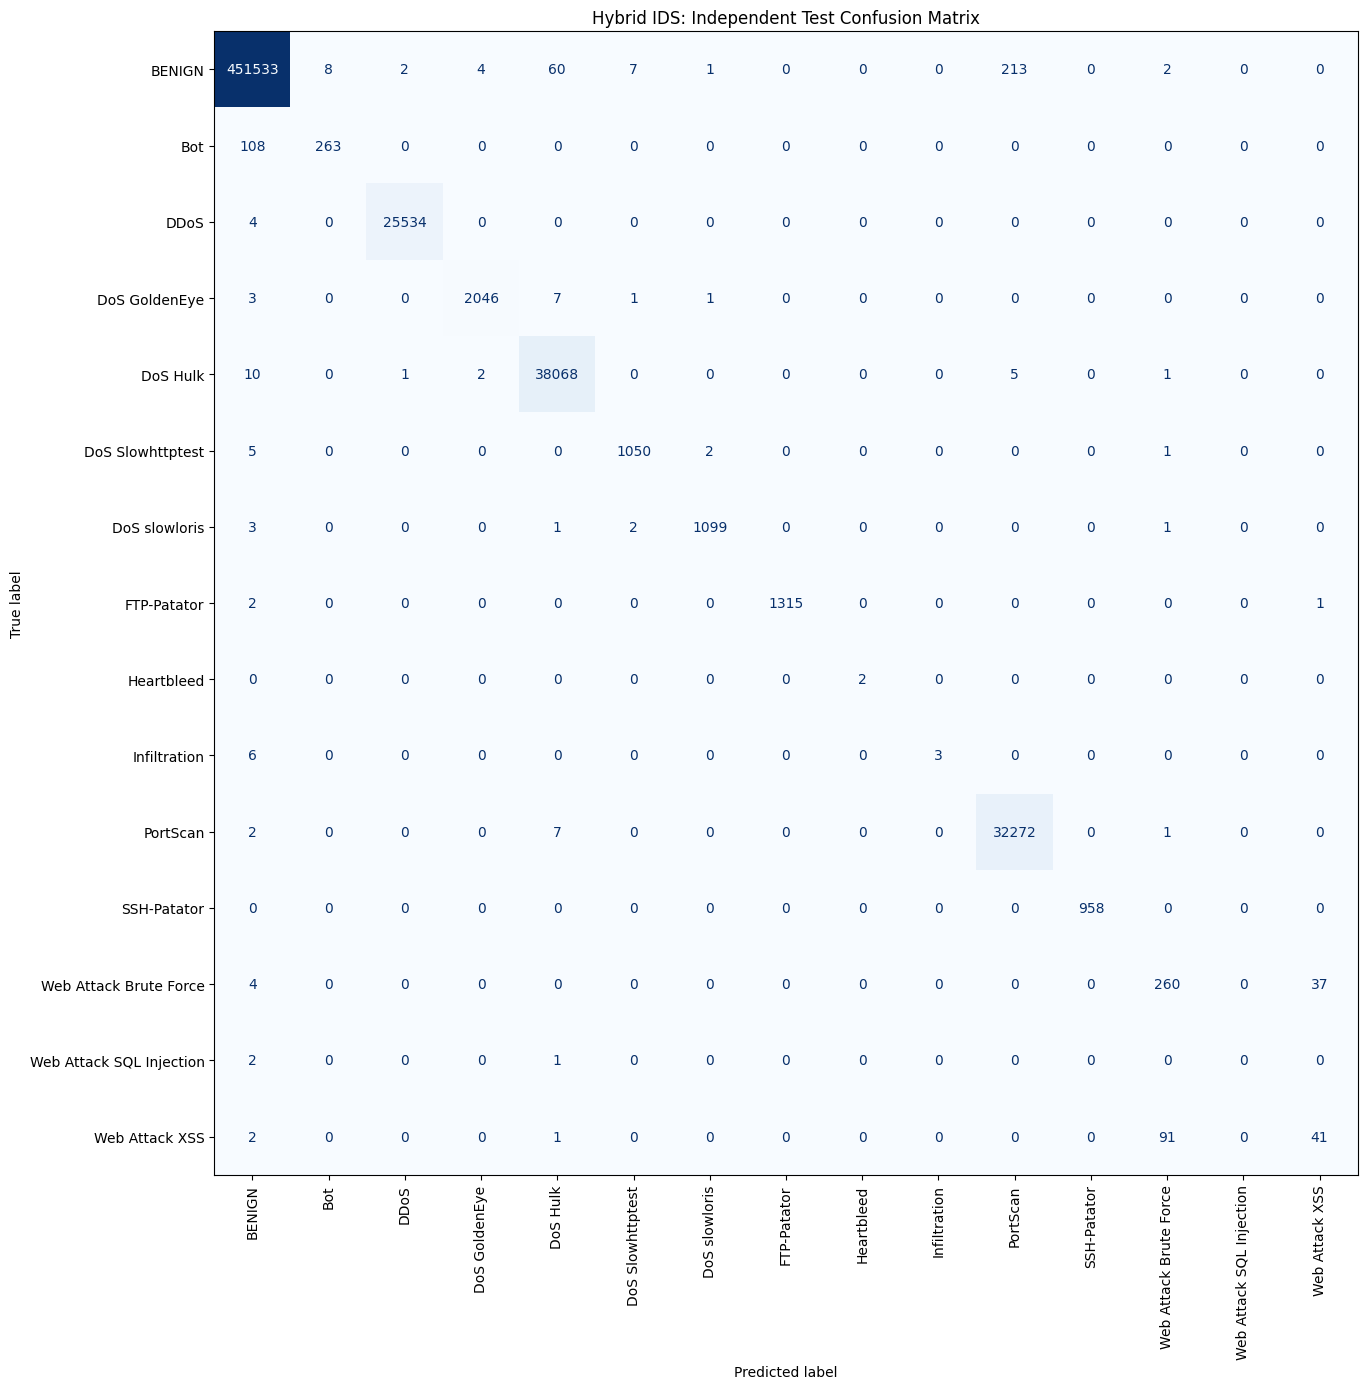

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(16, 14))

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=np.array(
        hybrid_metrics["confusion_matrix"]
    ),
    display_labels=CLASS_NAMES
)

cm_display.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Hybrid IDS: Independent Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [15]:
from IPython.display import display as show_table

routing_df = pd.DataFrame(routing_errors)

show_table(
    routing_df.sort_values(
        by="Routing Recall",
        ascending=True
    )
)

,Attack Class,Total Records,Routed as BENIGN,Routing Recall
8,Infiltration,9,6,0.3333
12,Web Attack SQL Injection,3,1,0.6667
0,Bot,371,108,0.7089
13,Web Attack XSS,135,2,0.9852
11,Web Attack Brute Force,301,4,0.9867
4,DoS Slowhttptest,1058,4,0.9962
5,DoS slowloris,1106,3,0.9973
6,FTP-Patator,1318,1,0.9992
2,DoS GoldenEye,2058,1,0.9995
1,DDoS,25538,4,0.9998
